# Task 3 — End-to-End Fraud Detection & Risk Analysis System
**QSkill Internship · Slab 2 (Intermediate)**

**Goal:** analyse financial transactions, understand how fraud differs from normal behaviour, build and compare classifiers that flag potentially fraudulent transactions, study their errors (false positives / false negatives), and convert model scores into a practical risk framework.

**Workflow**
1. Load & inspect data
2. Exploratory data analysis of transaction patterns and fraudulent behaviour
3. Cleaning & preprocessing
4. Feature engineering
5. Class-imbalance analysis and handling
6. Model building, comparison and tuning
7. Evaluation — precision, recall, F1, ROC-AUC, confusion matrices, precision-recall analysis
8. Operating-threshold selection (statistical and cost-based)
9. False positive / false negative analysis
10. Important fraud features
11. Risk analysis, observations and recommendations

> **Dataset note:** `../data/paysim_transactions.csv` follows the schema of the public Kaggle *PaySim Synthetic Financial Dataset* (mobile-money transactions: `step, type, amount, nameOrig, oldbalanceOrg, newbalanceOrg, nameDest, oldbalanceDest, newbalanceDest, isFraud, isFlaggedFraud`). The bundled file is a smaller practice sample with a higher fraud rate (~1 %) so models have enough fraud examples to learn from. To use the real 6.3-million-row file, save it under the same name — the notebook automatically samples it down for speed.

## 1. Setup & data loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: "{:,.2f}".format(x))
RS = 42

In [2]:
df = pd.read_csv("../data/paysim_transactions.csv")
if len(df) > 300_000:                       # the real PaySim file has 6.3M rows
    df = df.sample(300_000, random_state=RS).sort_values("step").reset_index(drop=True)
print("Shape:", df.shape)
df.head()

Shape: (60000, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrg,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,CASH_IN,"74,172.85",C356453709,"1,825.53","75,998.38",C436876793,563.48,"74,736.33",0,0
1,1,PAYMENT,"3,063.78",C417927151,0.00,0.00,M237545665,0.00,0.00,0,0
2,1,TRANSFER,"18,364.38",C970240394,"24,305.93","5,941.55",C418885187,"23,779.81","42,144.19",0,0
3,1,CASH_IN,"53,073.80",C355247062,"46,124.59","99,198.39",C418594362,"35,217.49","88,291.29",0,0
4,1,CASH_OUT,"11,335.98",C549779393,"51,015.82","39,679.84",C438096729,0.00,0.00,0,0


## 2. Data inspection

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            60000 non-null  int64  
 1   type            60000 non-null  str    
 2   amount          60000 non-null  float64
 3   nameOrig        60000 non-null  str    
 4   oldbalanceOrg   60000 non-null  float64
 5   newbalanceOrg   60000 non-null  float64
 6   nameDest        60000 non-null  str    
 7   oldbalanceDest  60000 non-null  float64
 8   newbalanceDest  60000 non-null  float64
 9   isFraud         60000 non-null  int64  
 10  isFlaggedFraud  60000 non-null  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 5.0 MB


In [4]:
print("Missing values  :", int(df.isna().sum().sum()))
print("Duplicate rows  :", int(df.duplicated().sum()))
print("Negative amounts:", int((df["amount"] < 0).sum()), "| zero amounts:", int((df["amount"] == 0).sum()))
print("Time span       : %d hourly steps (= %.1f days)" % (df["step"].max(), df["step"].max() / 24))
df.describe().T

Missing values  : 0
Duplicate rows  : 0
Negative amounts: 0 | zero amounts: 0
Time span       : 744 hourly steps (= 31.0 days)


,count,mean,std,min,25%,50%,75%,max
step,"60,000.00",376.79,214.73,1.00,189.00,376.00,564.00,744.00
amount,"60,000.00","78,429.54","180,529.43",147.41,"6,842.15","27,236.06","87,888.94","10,298,634.41"
oldbalanceOrg,"60,000.00","188,878.37","668,633.48",0.00,"9,990.58","39,156.93","143,821.76","39,479,812.58"
newbalanceOrg,"60,000.00","175,068.74","584,993.30",0.00,"4,075.63","35,908.08","163,792.73","36,797,201.91"
oldbalanceDest,"60,000.00","177,417.06","1,871,997.78",0.00,0.00,0.00,"27,488.90","189,627,212.54"
newbalanceDest,"60,000.00","239,704.00","1,881,130.06",0.00,0.00,"31,585.05","148,448.45","189,753,497.55"
isFraud,"60,000.00",0.01,0.10,0.00,0.00,0.00,0.00,1.00
isFlaggedFraud,"60,000.00",0.02,0.15,0.00,0.00,0.00,0.00,1.00


Legitimate: 59353 | Fraud: 647 | fraud rate = 1.08%  (1 fraud per 91 legitimate)


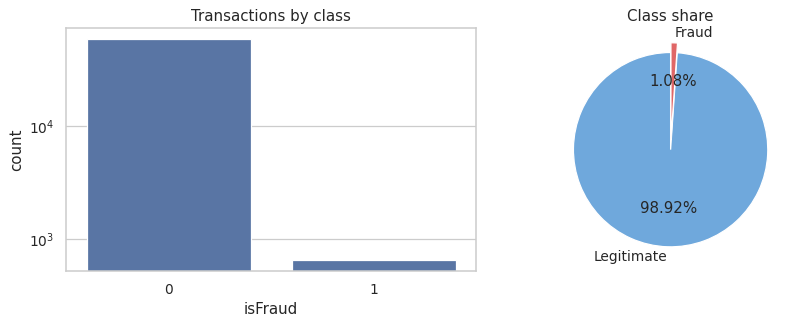

In [5]:
vc = df["isFraud"].value_counts()
print("Legitimate:", vc[0], "| Fraud:", vc[1], "| fraud rate = %.2f%%  (1 fraud per %d legitimate)" % (df["isFraud"].mean() * 100, vc[0] // vc[1]))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
sns.countplot(x="isFraud", data=df, ax=ax[0]); ax[0].set_title("Transactions by class"); ax[0].set_yscale("log")
ax[1].pie(vc, labels=["Legitimate", "Fraud"], autopct="%1.2f%%", colors=["#6fa8dc", "#e06666"], startangle=90, explode=(0, 0.1))
ax[1].set_title("Class share")
plt.tight_layout()
plt.show()

Fraud is **extremely rare** — a model that always predicts "legitimate" would be ~99 % accurate and completely useless. Accuracy is therefore ignored; we focus on precision, recall, F1, ROC-AUC and precision-recall analysis.

## 3. Exploratory data analysis — transaction patterns and fraudulent behaviour

### 3.1 Transaction type

In [6]:
t = df.groupby("type")["isFraud"].agg(transactions="size", frauds="sum", fraud_rate_pct=lambda s: s.mean() * 100)
t["share_of_all_fraud_%"] = t["frauds"] / t["frauds"].sum() * 100
t.sort_values("frauds", ascending=False)

,transactions,frauds,fraud_rate_pct,share_of_all_fraud_%
type,,,,
TRANSFER,4836,374,7.73,57.81
CASH_OUT,20963,273,1.30,42.19
CASH_IN,13114,0,0.00,0.00
DEBIT,596,0,0.00,0.00
PAYMENT,20491,0,0.00,0.00


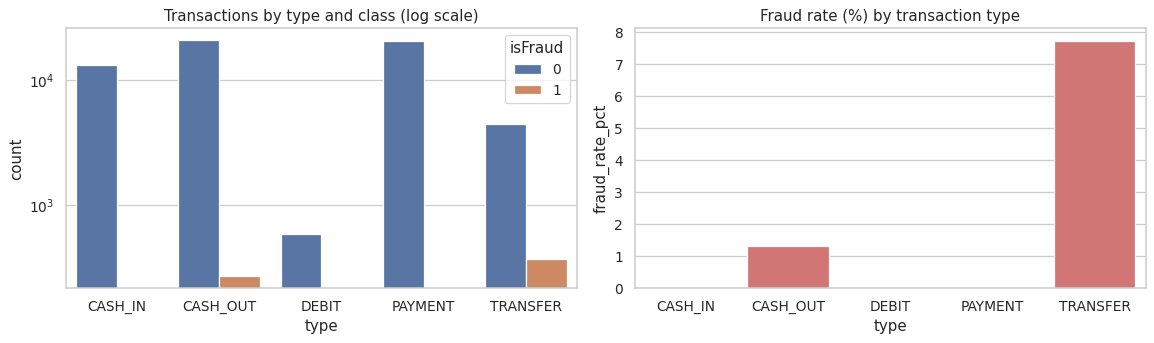

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x="type", hue="isFraud", data=df, ax=ax[0], order=t.index); ax[0].set_yscale("log"); ax[0].set_title("Transactions by type and class (log scale)")
sns.barplot(x=t.index, y=t["fraud_rate_pct"], ax=ax[1], color="#e06666"); ax[1].set_title("Fraud rate (%) by transaction type")
plt.tight_layout()
plt.show()

Fraud occurs **only in `TRANSFER` and `CASH_OUT`** — the classic pattern of an attacker moving money to another account and then cashing it out. The other types can be handled by simple rules.

### 3.2 Transaction amount

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,"25,152.00","94,389.00","195,639.00",191.00,"18,049.00","41,820.00","97,817.00","9,405,659.00"
1,647.00,"577,265.00","845,580.00","24,005.00","173,652.00","332,376.00","654,976.00","10,298,634.00"


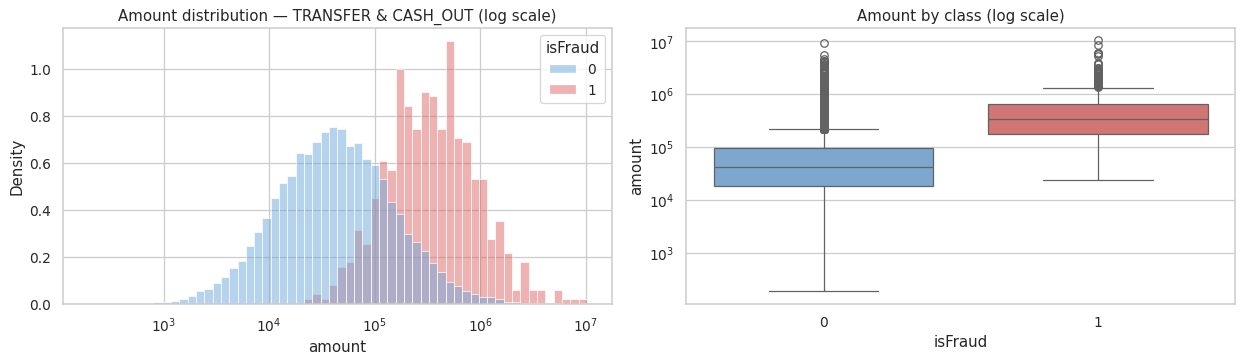

In [8]:
risky = df[df["type"].isin(["TRANSFER", "CASH_OUT"])]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
sns.histplot(data=risky, x="amount", hue="isFraud", bins=60, log_scale=True, stat="density", common_norm=False, ax=ax[0], palette=["#6fa8dc", "#e06666"])
ax[0].set_title("Amount distribution — TRANSFER & CASH_OUT (log scale)")
sns.boxplot(x="isFraud", y="amount", data=risky, ax=ax[1], palette=["#6fa8dc", "#e06666"]); ax[1].set_yscale("log")
ax[1].set_title("Amount by class (log scale)")
plt.tight_layout()
plt.show()
risky.groupby("isFraud")["amount"].describe().round(0)

### 3.3 Timing

Fraud rate during 00:00-05:59: 7.69%  | rest of day: 0.63%


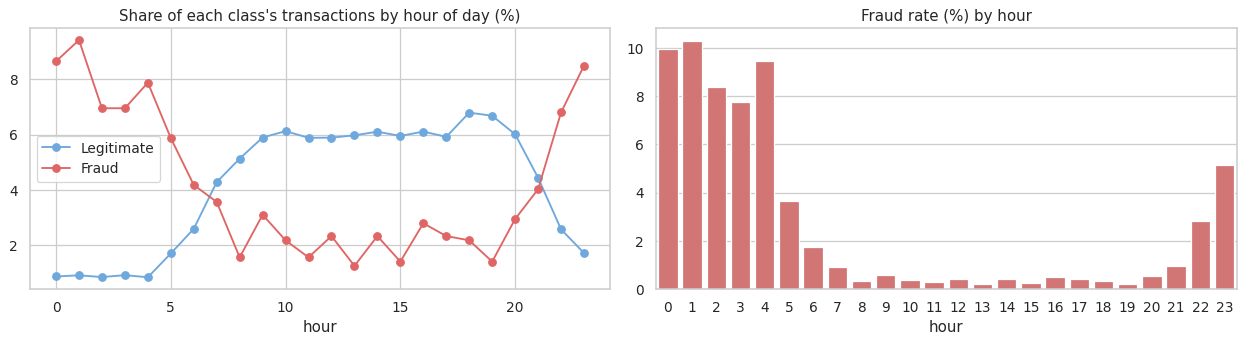

In [9]:
df["hour"] = (df["step"] - 1) % 24
df["day"] = (df["step"] - 1) // 24

hour_share = df.groupby(["isFraud", "hour"]).size().groupby(level=0).transform(lambda s: s / s.sum() * 100).unstack(0)
hour_share.columns = ["Legitimate", "Fraud"]
fraud_rate_hour = df.groupby("hour")["isFraud"].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
hour_share.plot(ax=ax[0], marker="o", color=["#6fa8dc", "#e06666"]); ax[0].set_title("Share of each class's transactions by hour of day (%)"); ax[0].set_xlabel("hour")
sns.barplot(x=fraud_rate_hour.index, y=fraud_rate_hour.values, ax=ax[1], color="#e06666"); ax[1].set_title("Fraud rate (%) by hour"); ax[1].set_xlabel("hour")
plt.tight_layout()
plt.show()
night = df["hour"] < 6
print("Fraud rate during 00:00-05:59: %.2f%%  | rest of day: %.2f%%" % (df.loc[night, "isFraud"].mean() * 100, df.loc[~night, "isFraud"].mean() * 100))

### 3.4 Balance behaviour

In [10]:
r = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()
r["orig_emptied"] = (r["oldbalanceOrg"] > 0) & (r["newbalanceOrg"] == 0)
r["dest_balance_zero_before"] = r["oldbalanceDest"] == 0
r["dest_balance_unchanged"] = r["newbalanceDest"] == r["oldbalanceDest"]

for col in ["orig_emptied", "dest_balance_zero_before", "dest_balance_unchanged"]:
    print(col)
    print(r.groupby(col)["isFraud"].agg(transactions="size", fraud_rate_pct=lambda s: s.mean() * 100).round(2))
    print()

orig_emptied
              transactions  fraud_rate_pct
orig_emptied                              
False                23956            0.49
True                  1843           28.76

dest_balance_zero_before
                          transactions  fraud_rate_pct
dest_balance_zero_before                              
False                            15199            1.88
True                             10600            3.41

dest_balance_unchanged
                        transactions  fraud_rate_pct
dest_balance_unchanged                              
False                          21711            1.59
True                            4088            7.36



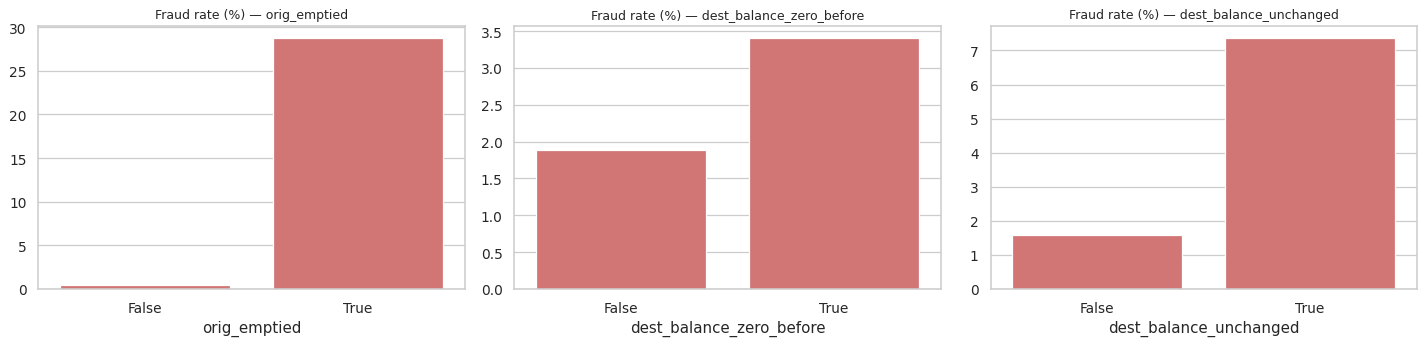

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ["orig_emptied", "dest_balance_zero_before", "dest_balance_unchanged"]):
    rate = r.groupby(col)["isFraud"].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=a, color="#e06666")
    a.set_title("Fraud rate (%) — " + col, fontsize=10)
plt.tight_layout()
plt.show()

Frauds typically **drain the sender's whole balance** and send it to a destination account that is empty or whose balance does not increase (a mule account that immediately moves the money on). These are strong behavioural signals that the engineered features in Section 5 capture explicitly.

### 3.5 The existing business rule (`isFlaggedFraud`)

In [12]:
print("Rule: flag TRANSFER transactions above 200,000\n")
rule_cm = confusion_matrix(df["isFraud"], df["isFlaggedFraud"])
print(pd.DataFrame(rule_cm, index=["actual legit", "actual fraud"], columns=["flagged: no", "flagged: yes"]))
print("\nRule precision = %.3f | recall = %.3f" % (precision_score(df["isFraud"], df["isFlaggedFraud"]), recall_score(df["isFraud"], df["isFlaggedFraud"])))

Rule: flag TRANSFER transactions above 200,000

              flagged: no  flagged: yes
actual legit        58279          1074
actual fraud          389           258

Rule precision = 0.194 | recall = 0.399


A single fixed threshold both **misses much of the fraud** (low recall) and **floods analysts with false alarms** (low precision). This is the baseline the machine-learning models have to beat. The column is *not* used as a model feature.

## 4. Cleaning & preprocessing
- No missing values or duplicates were found. Zero-valued balances are **meaningful** here (e.g. a drained account or an empty destination), so they are kept rather than "fixed".
- `nameOrig` / `nameDest` are unique identifiers and would only cause over-fitting; only the *type* of destination (customer `C…` vs merchant `M…`) is kept.
- `isFlaggedFraud` is an output of an existing rule, not an input available at prediction time → excluded.
- `type` is one-hot encoded.

## 5. Feature engineering
| Feature | Meaning |
|---|---|
| `errorBalanceOrig` | `newbalanceOrg + amount − oldbalanceOrg` — accounting mismatch on the sender side |
| `errorBalanceDest` | `oldbalanceDest + amount − newbalanceDest` — mismatch on the receiver side |
| `orig_emptied` | sender's balance was fully drained |
| `amount_to_balance_ratio` | amount relative to sender's balance (capped at 10) |
| `dest_zero_before` / `dest_no_change` | receiver account empty before / balance unchanged afterwards |
| `dest_is_merchant` | destination is a merchant account |
| `hour`, `is_night` | hour of day, and a 00:00–05:59 flag |
| `log_amount` | log-scaled amount |

In [13]:
d = df.copy()
d["errorBalanceOrig"] = d["newbalanceOrg"] + d["amount"] - d["oldbalanceOrg"]
d["errorBalanceDest"] = d["oldbalanceDest"] + d["amount"] - d["newbalanceDest"]
d["orig_emptied"] = ((d["oldbalanceOrg"] > 0) & (d["newbalanceOrg"] == 0)).astype(int)
d["amount_to_balance_ratio"] = (d["amount"] / (d["oldbalanceOrg"] + 1)).clip(upper=10)
d["dest_zero_before"] = (d["oldbalanceDest"] == 0).astype(int)
d["dest_no_change"] = ((d["newbalanceDest"] == d["oldbalanceDest"]) & (d["amount"] > 0)).astype(int)
d["dest_is_merchant"] = d["nameDest"].str.startswith("M").astype(int)
d["is_night"] = (d["hour"] < 6).astype(int)
d["log_amount"] = np.log1p(d["amount"])
d = pd.get_dummies(d, columns=["type"], prefix="type", dtype=int)

drop_cols = ["nameOrig", "nameDest", "isFlaggedFraud", "step", "day"]
y = d["isFraud"]
X = d.drop(columns=drop_cols + ["isFraud"])
print("Feature matrix:", X.shape)
print(list(X.columns))

Feature matrix: (60000, 20)
['amount', 'oldbalanceOrg', 'newbalanceOrg', 'oldbalanceDest', 'newbalanceDest', 'hour', 'errorBalanceOrig', 'errorBalanceDest', 'orig_emptied', 'amount_to_balance_ratio', 'dest_zero_before', 'dest_no_change', 'dest_is_merchant', 'is_night', 'log_amount', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


orig_emptied        0.37
amount              0.29
errorBalanceDest    0.29
type_TRANSFER       0.19
log_amount          0.17
is_night            0.17
hour               -0.08
dest_is_merchant   -0.07
type_PAYMENT       -0.07
oldbalanceOrg       0.06
Name: isFraud, dtype: float64

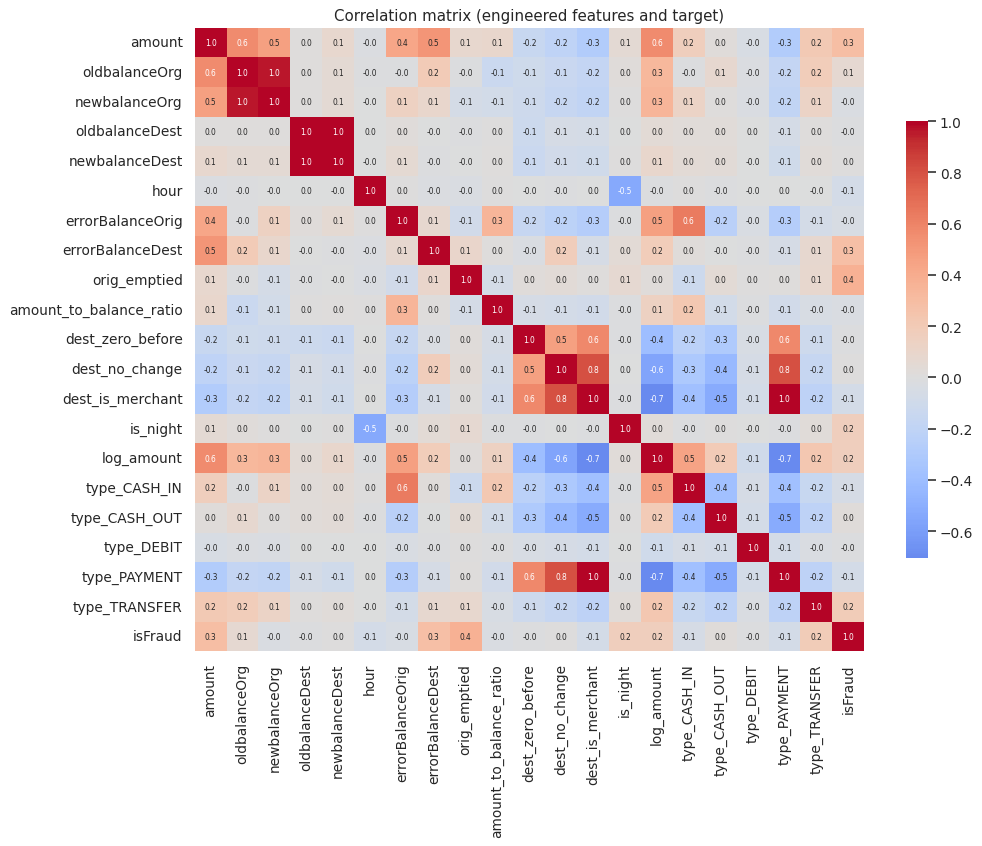

In [14]:
fig, ax = plt.subplots(figsize=(12, 9))
corr = pd.concat([X, y], axis=1).corr()
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, annot=True, fmt=".1f", annot_kws={"size": 6}, cbar_kws={"shrink": 0.7})
ax.set_title("Correlation matrix (engineered features and target)")
plt.show()
corr["isFraud"].drop("isFraud").sort_values(key=abs, ascending=False).head(10).round(3)

## 6. Train / test split and class-imbalance handling
A stratified 75/25 split keeps the same fraud rate in both sets. The test set is only used at the end.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RS)
print("Train: %d rows, %d frauds (%.2f%%)" % (len(X_train), y_train.sum(), y_train.mean() * 100))
print("Test : %d rows, %d frauds (%.2f%%)" % (len(X_test), y_test.sum(), y_test.mean() * 100))
Xtr, ytr = X_train.reset_index(drop=True), y_train.reset_index(drop=True)

Train: 45000 rows, 485 frauds (1.08%)
Test : 15000 rows, 162 frauds (1.08%)


### 6.1 Comparing imbalance strategies
The same Random Forest is trained with four strategies. Re-sampling is applied **only inside each training fold** (3-fold stratified CV on the training data); validation folds are never re-sampled. Because the positive class is rare, **PR-AUC (average precision)** is the key metric alongside precision, recall and F1.

In [16]:
def resample_fold(Xf, yf, how, seed=RS):
    rng = np.random.RandomState(seed)
    pos, neg = np.where(yf == 1)[0], np.where(yf == 0)[0]
    if how == "oversample":
        idx = np.concatenate([neg, pos, rng.choice(pos, len(neg) - len(pos), replace=True)])
    elif how == "undersample":
        idx = np.concatenate([pos, rng.choice(neg, min(len(neg), len(pos) * 10), replace=False)])   # 10:1 ratio
    else:
        idx = np.arange(len(yf))
    return Xf.iloc[idx], yf.iloc[idx]

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
rows = []
for name, how, cw in [("None", None, None), ("Class weights", None, "balanced_subsample"),
                      ("Random oversampling", "oversample", None), ("Random undersampling (10:1)", "undersample", None)]:
    sc = {"precision": [], "recall": [], "f1": [], "pr_auc": []}
    for tr, va in skf.split(Xtr, ytr):
        Xf, yf = resample_fold(Xtr.iloc[tr], ytr.iloc[tr], how)
        rf = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=3, class_weight=cw, random_state=RS, n_jobs=-1).fit(Xf, yf)
        p = rf.predict_proba(Xtr.iloc[va])[:, 1]
        pred = (p >= 0.5).astype(int)
        sc["precision"].append(precision_score(ytr.iloc[va], pred, zero_division=0))
        sc["recall"].append(recall_score(ytr.iloc[va], pred))
        sc["f1"].append(f1_score(ytr.iloc[va], pred))
        sc["pr_auc"].append(average_precision_score(ytr.iloc[va], p))
    rows.append({"strategy": name, **{k: np.mean(v) for k, v in sc.items()}})
imb = pd.DataFrame(rows).set_index("strategy").round(3)
imb

,precision,recall,f1,pr_auc
strategy,,,,
None,0.83,0.67,0.74,0.85
Class weights,0.61,0.89,0.72,0.82
Random oversampling,0.56,0.91,0.69,0.82
Random undersampling (10:1),0.59,0.89,0.71,0.82


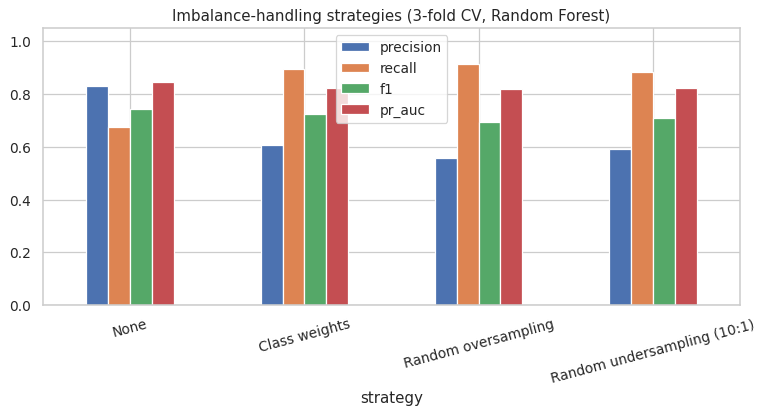

In [17]:
imb[["precision", "recall", "f1", "pr_auc"]].plot(kind="bar", figsize=(10, 4), rot=15)
plt.title("Imbalance-handling strategies (3-fold CV, Random Forest)")
plt.ylim(0, 1.05)
plt.show()

**Reading the table:** training on the raw data gives the highest precision but misses a noticeably larger share of fraud (lower recall) at the default 0.5 threshold. Every imbalance strategy mainly **shifts the operating point** — more recall, more false alarms — while the threshold-independent PR-AUC stays similar. Because a missed fraud is usually costlier than a false alarm, **class weights** are used in all models below: they push the model towards recall without duplicating or discarding any transactions. The precision/recall balance is then fine-tuned explicitly with the decision threshold in Section 10. *(SMOTE from `imbalanced-learn` can be added as a further experiment.)*

## 7. Building and comparing multiple classifiers

In [18]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"), True),
    "Decision Tree":       (DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, class_weight="balanced", random_state=RS), False),
    "Random Forest":       (RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=3, class_weight="balanced_subsample", random_state=RS, n_jobs=-1), False),
    "Hist Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=RS), False),
}
scoring = {"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}

def make_pipe(est, scale):
    steps = ([("sc", StandardScaler())] if scale else []) + [("model", est)]
    return Pipeline(steps)

rows = []
for name, (est, scale) in models.items():
    cv = cross_validate(make_pipe(est, scale), Xtr, ytr, cv=skf, scoring=scoring)
    rows.append({"model": name, **{m: cv["test_" + m].mean() for m in scoring}})
cv_table = pd.DataFrame(rows).set_index("model").sort_values("pr_auc", ascending=False).round(3)
cv_table

,precision,recall,f1,roc_auc,pr_auc
model,,,,,
Logistic Regression,0.34,0.98,0.51,1.00,0.84
Random Forest,0.66,0.86,0.75,1.00,0.83
Hist Gradient Boosting,0.58,0.91,0.70,0.99,0.80
Decision Tree,0.48,0.93,0.63,0.96,0.66


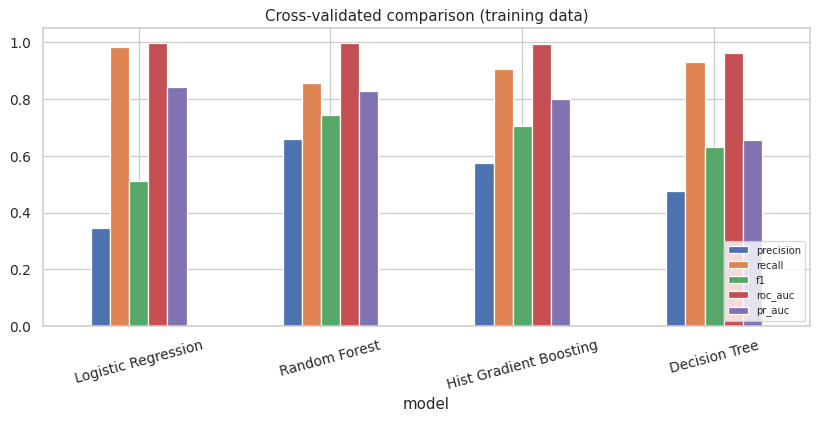

In [19]:
cv_table.plot(kind="bar", figsize=(11, 4.3), rot=15)
plt.title("Cross-validated comparison (training data)")
plt.ylim(0, 1.05)
plt.legend(loc="lower right", fontsize=8)
plt.show()

## 8. Hyper-parameter tuning
The two best models by cross-validated PR-AUC are tuned with `RandomizedSearchCV` using **average precision** as the objective, which is more informative than ROC-AUC for rare-event problems.

In [20]:
space = {
    "Random Forest": {"model__n_estimators": [150, 250], "model__max_depth": [8, 12, 16, None],
                      "model__min_samples_leaf": [1, 3, 5, 10], "model__max_features": ["sqrt", 0.5]},
    "Hist Gradient Boosting": {"model__learning_rate": [0.03, 0.06, 0.1, 0.2], "model__max_depth": [None, 4, 6, 8],
                               "model__max_leaf_nodes": [15, 31, 63], "model__min_samples_leaf": [10, 20, 40],
                               "model__l2_regularization": [0, 0.1, 1.0]},
    "Decision Tree": {"model__max_depth": [4, 6, 8, 12], "model__min_samples_leaf": [3, 5, 10, 20]},
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100]},
}
top2 = cv_table.index[:2].tolist()
print("Tuning:", top2)

tuned, tuned_cv = {}, {}
for name in top2:
    est, scale = models[name]
    rs = RandomizedSearchCV(make_pipe(est, scale), space[name], n_iter=8, scoring="average_precision",
                            cv=StratifiedKFold(3, shuffle=True, random_state=RS), random_state=RS, n_jobs=1)
    rs.fit(Xtr, ytr)
    tuned["Tuned " + name] = rs.best_estimator_
    tuned_cv["Tuned " + name] = rs.best_score_
    print("%-26s CV PR-AUC = %.3f  %s" % (name, rs.best_score_, {k.replace("model__", ""): v for k, v in rs.best_params_.items()}))

best_name = max(tuned_cv, key=tuned_cv.get)
print("\nSelected model (highest CV PR-AUC, chosen without looking at the test set):", best_name)

Tuning: ['Logistic Regression', 'Random Forest']
Logistic Regression        CV PR-AUC = 0.847  {'C': 100}
Random Forest              CV PR-AUC = 0.838  {'n_estimators': 150, 'min_samples_leaf': 3, 'max_features': 0.5, 'max_depth': None}

Selected model (highest CV PR-AUC, chosen without looking at the test set): Tuned Logistic Regression


## 9. Evaluation on the untouched test set
Metrics at the default 0.5 threshold, compared with the existing `isFlaggedFraud` rule and an untuned Logistic Regression baseline.

In [21]:
def evaluate(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred), "roc_auc": roc_auc_score(y_true, proba), "pr_auc": average_precision_score(y_true, proba)}

baseline_lr = make_pipe(*models["Logistic Regression"]).fit(Xtr, ytr)
final = {"Baseline: Logistic Regression": baseline_lr, **tuned}

probas = {n: m.predict_proba(X_test)[:, 1] for n, m in final.items()}
rows = {n: evaluate(y_test, p) for n, p in probas.items()}

rule_pred = df.loc[X_test.index, "isFlaggedFraud"]
rows["Existing rule (isFlaggedFraud)"] = {"precision": precision_score(y_test, rule_pred, zero_division=0), "recall": recall_score(y_test, rule_pred),
                                          "f1": f1_score(y_test, rule_pred), "roc_auc": np.nan, "pr_auc": np.nan}
test_table = pd.DataFrame(rows).T.round(3)
test_table

,precision,recall,f1,roc_auc,pr_auc
Baseline: Logistic Regression,0.38,0.97,0.55,0.99,0.86
Tuned Logistic Regression,0.42,0.99,0.59,1.00,0.87
Tuned Random Forest,0.77,0.87,0.82,0.99,0.87
Existing rule (isFlaggedFraud),0.21,0.42,0.28,NaN,NaN


### 9.1 Confusion matrices

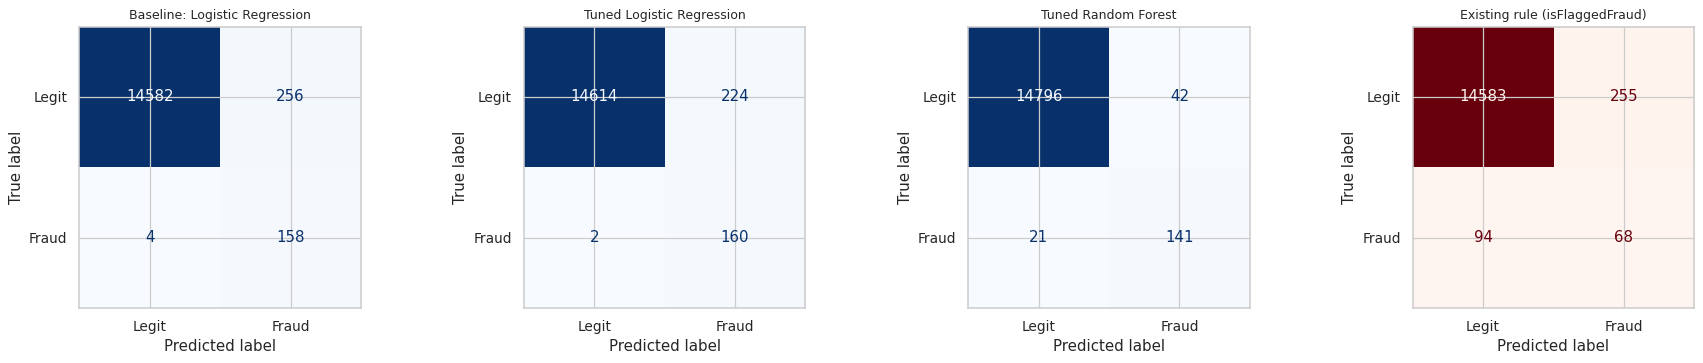

In [22]:
fig, axes = plt.subplots(1, len(final) + 1, figsize=(5 * (len(final) + 1), 4.2))
for ax, (name, p) in zip(axes, probas.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (p >= 0.5).astype(int), display_labels=["Legit", "Fraud"], cmap="Blues", ax=ax, colorbar=False, values_format="d")
    ax.set_title(name, fontsize=10)
ConfusionMatrixDisplay.from_predictions(y_test, rule_pred, display_labels=["Legit", "Fraud"], cmap="Reds", ax=axes[-1], colorbar=False, values_format="d")
axes[-1].set_title("Existing rule (isFlaggedFraud)", fontsize=10)
plt.tight_layout()
plt.show()

### 9.2 ROC and precision-recall curves

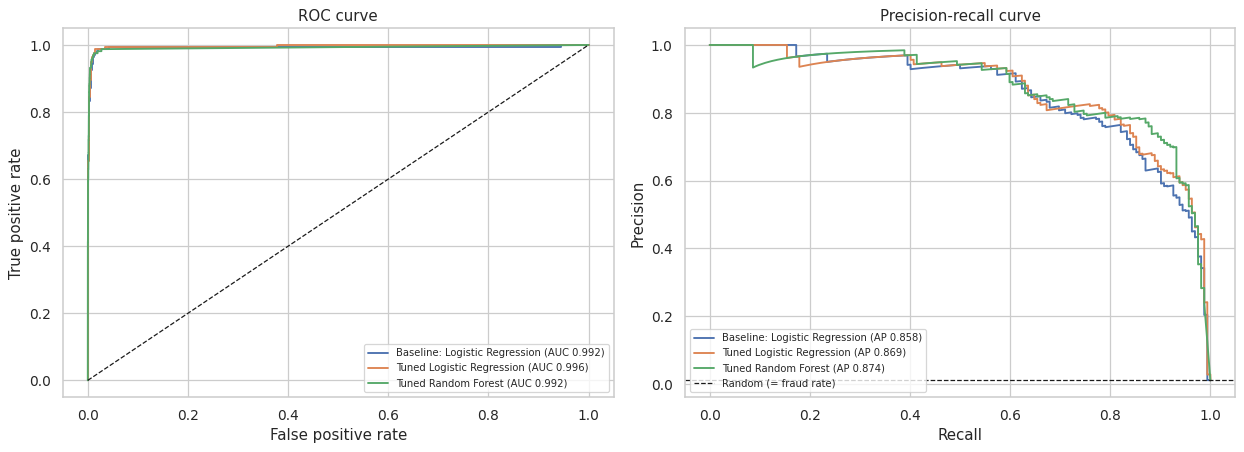

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label="%s (AUC %.3f)" % (name, roc_auc_score(y_test, p)))
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, label="%s (AP %.3f)" % (name, average_precision_score(y_test, p)))
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].set_title("ROC curve"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="Random (= fraud rate)")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-recall curve"); ax[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

ROC-AUC looks excellent for almost any decent model because legitimate transactions are so numerous; the **precision-recall curve** is the more honest picture of how many alerts are real fraud at each level of recall.

## 10. Choosing the operating threshold
A probability threshold turns a score into an alert. Two thresholds are derived from **cross-validated predictions on the training set only**:
1. **F1-optimal** — the best statistical balance of precision and recall.
2. **Cost-optimal** — minimises *money lost to missed fraud (the transaction amount) + a fixed review cost per false alert*. The review cost below is an assumption and should be replaced by the real figure.

F1-optimal threshold   : 0.98
Cost-optimal threshold : 0.12


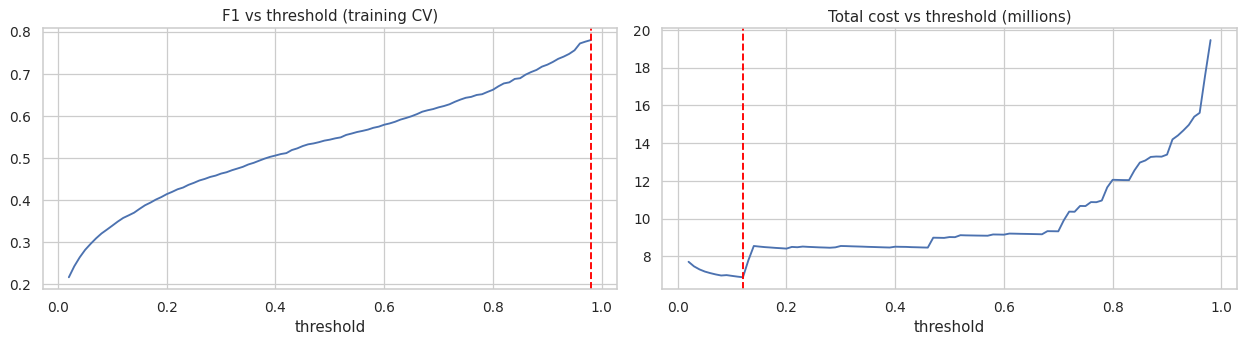

In [24]:
REVIEW_COST = 500          # assumed cost of manually reviewing / contacting the customer for one false alert
best_model = final[best_name]
oof = cross_val_predict(best_model, Xtr, ytr, cv=skf, method="predict_proba")[:, 1]
amt_tr = Xtr["amount"].values

grid = np.linspace(0.02, 0.98, 97)
f1_grid, cost_grid = [], []
for t in grid:
    pred = oof >= t
    f1_grid.append(f1_score(ytr, pred))
    fn_cost = amt_tr[(~pred) & (ytr.values == 1)].sum()
    fp_cost = REVIEW_COST * ((pred) & (ytr.values == 0)).sum()
    cost_grid.append(fn_cost + fp_cost)

thr_f1 = grid[int(np.argmax(f1_grid))]
thr_cost = grid[int(np.argmin(cost_grid))]
print("F1-optimal threshold   : %.2f" % thr_f1)
print("Cost-optimal threshold : %.2f" % thr_cost)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(grid, f1_grid); ax[0].axvline(thr_f1, color="red", ls="--"); ax[0].set_title("F1 vs threshold (training CV)"); ax[0].set_xlabel("threshold")
ax[1].plot(grid, np.array(cost_grid) / 1e6); ax[1].axvline(thr_cost, color="red", ls="--"); ax[1].set_title("Total cost vs threshold (millions)"); ax[1].set_xlabel("threshold")
plt.tight_layout()
plt.show()

In [25]:
p_best = probas[best_name]
amt_te = X_test["amount"].values
rows = {}
for label, t in [("Default 0.5", 0.5), ("F1-optimal %.2f" % thr_f1, thr_f1), ("Cost-optimal %.2f" % thr_cost, thr_cost)]:
    pred = p_best >= t
    cm = confusion_matrix(y_test, pred)
    rows[label] = {**evaluate(y_test, p_best, t), "alerts": int(pred.sum()), "false_positives": int(cm[0, 1]), "missed_frauds": int(cm[1, 0]),
                   "fraud_amount_caught_%": amt_te[pred & (y_test.values == 1)].sum() / amt_te[y_test.values == 1].sum() * 100}
thr_table = pd.DataFrame(rows).T.round(3)
print("Model:", best_name)
thr_table

Model: Tuned Logistic Regression


,precision,recall,f1,roc_auc,pr_auc,alerts,false_positives,missed_frauds,fraud_amount_caught_%
Default 0.5,0.42,0.99,0.59,1.00,0.87,384.00,224.00,2.00,88.96
F1-optimal 0.98,0.75,0.84,0.79,1.00,0.87,182.00,46.00,26.00,84.55
Cost-optimal 0.12,0.22,0.99,0.35,1.00,0.87,746.00,585.00,1.00,89.04


**Why not just 0.5?** Class weighting pushes predicted probabilities upwards, so the default 0.5 cut-off produces many more alerts than necessary. Moving the threshold trades **false positives against missed frauds** — the table shows how the number of alerts, false alarms, missed frauds and the share of fraud *money* caught change at each operating point. Pick the row that matches the organisation's appetite for review workload versus fraud loss.

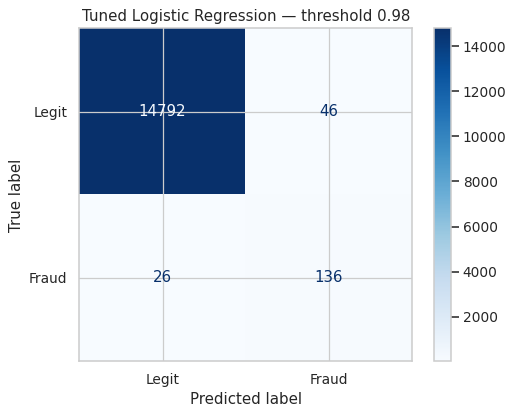

In [26]:
OP_THR = thr_f1          # operating point used for the error analysis below
pred_op = (p_best >= OP_THR).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test, pred_op, display_labels=["Legit", "Fraud"], cmap="Blues", values_format="d")
plt.title("%s — threshold %.2f" % (best_name, OP_THR))
plt.show()

## 11. False positive and false negative analysis
- **False positive (FP):** a legitimate transaction that was flagged → customer friction and analyst workload.
- **False negative (FN):** a fraud that slipped through → direct financial loss.

The groups are compared on the key features to understand *why* the model errs.

In [27]:
te = X_test.copy()
te["isFraud"] = y_test.values
te["proba"] = p_best
te["pred"] = pred_op
te["type"] = df.loc[X_test.index, "type"].values
te["group"] = np.select([(te.isFraud == 1) & (te.pred == 1), (te.isFraud == 1) & (te.pred == 0),
                         (te.isFraud == 0) & (te.pred == 1), (te.isFraud == 0) & (te.pred == 0)],
                        ["TP (fraud caught)", "FN (fraud missed)", "FP (false alarm)", "TN (correct pass)"], default="")
print(te["group"].value_counts().to_string())

cmp_cols = ["amount", "oldbalanceOrg", "orig_emptied", "dest_zero_before", "dest_no_change", "amount_to_balance_ratio", "is_night", "proba"]
te.groupby("group")[cmp_cols].mean().round(3).T

group
TN (correct pass)    14792
TP (fraud caught)      136
FP (false alarm)        46
FN (fraud missed)       26


group,FN (fraud missed),FP (false alarm),TN (correct pass),TP (fraud caught)
amount,"558,184.86","356,339.14","70,882.18","583,938.06"
oldbalanceOrg,"690,317.12","367,121.89","177,569.27","596,160.42"
orig_emptied,0.58,0.72,0.04,0.86
dest_zero_before,0.50,0.61,0.61,0.54
dest_no_change,0.31,0.24,0.45,0.47
amount_to_balance_ratio,0.92,0.98,1.92,0.98
is_night,0.19,0.15,0.06,0.49
proba,0.79,0.99,0.02,1.00


In [28]:
fn = te[te["group"] == "FN (fraud missed)"]
fp = te[te["group"] == "FP (false alarm)"]
tp = te[te["group"] == "TP (fraud caught)"]

print("Missed frauds (FN): %d | money missed: {:,.0f} | share of all fraud money: %.1f%%".format(fn["amount"].sum()) %
      (len(fn), fn["amount"].sum() / te.loc[te.isFraud == 1, "amount"].sum() * 100))
print("False alarms  (FP): %d | = %.3f%% of all legitimate transactions" % (len(fp), len(fp) / (te.isFraud == 0).sum() * 100))
print()
print("Transaction type of FN :", fn["type"].value_counts().to_dict())
print("Transaction type of FP :", fp["type"].value_counts().to_dict())
print("\nFN: median amount = {:,.0f} vs TP median = {:,.0f}".format(fn["amount"].median(), tp["amount"].median()) if len(fn) and len(tp) else "")
print("FN: sender emptied = %.0f%% | TP: sender emptied = %.0f%%" % (fn["orig_emptied"].mean() * 100, tp["orig_emptied"].mean() * 100) if len(fn) and len(tp) else "")
print("FP: sender emptied = %.0f%% | FP at night = %.0f%%" % (fp["orig_emptied"].mean() * 100, fp["is_night"].mean() * 100) if len(fp) else "")

Missed frauds (FN): 26 | money missed: 14,512,806 | share of all fraud money: 15.5%
False alarms  (FP): 46 | = 0.310% of all legitimate transactions

Transaction type of FN : {'CASH_OUT': 19, 'TRANSFER': 7}
Transaction type of FP : {'CASH_OUT': 25, 'TRANSFER': 21}

FN: median amount = 111,849 vs TP median = 393,812
FN: sender emptied = 58% | TP: sender emptied = 86%
FP: sender emptied = 72% | FP at night = 15%


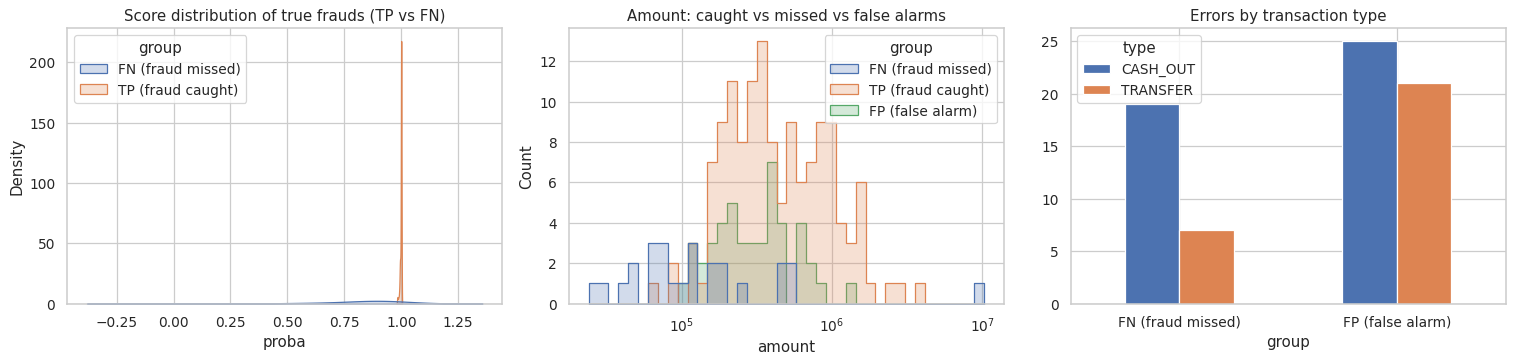

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.kdeplot(data=te[te.isFraud == 1], x="proba", hue="group", common_norm=False, fill=True, ax=ax[0], warn_singular=False)
ax[0].set_title("Score distribution of true frauds (TP vs FN)")
sns.histplot(data=te[te["group"].isin(["FP (false alarm)", "TP (fraud caught)", "FN (fraud missed)"])], x="amount", hue="group", log_scale=True, bins=40, ax=ax[1], element="step")
ax[1].set_title("Amount: caught vs missed vs false alarms")
te[te["group"].isin(["FP (false alarm)", "FN (fraud missed)"])].groupby(["group", "type"]).size().unstack(fill_value=0).plot(kind="bar", ax=ax[2], rot=0)
ax[2].set_title("Errors by transaction type")
plt.tight_layout()
plt.show()

In [30]:
print("Examples of missed frauds (lowest model scores):")
cols = ["type", "amount", "oldbalanceOrg", "newbalanceOrg", "oldbalanceDest", "newbalanceDest", "hour", "proba"]
display_cols = cols
fn.sort_values("proba")[display_cols].head(8)

Examples of missed frauds (lowest model scores):


,type,amount,oldbalanceOrg,newbalanceOrg,oldbalanceDest,newbalanceDest,hour,proba
5761,CASH_OUT,"10,298,634.41","13,042,547.43","2,743,913.02","5,895.62","5,895.62",0,0.00
30715,CASH_OUT,"69,045.88","86,519.30","17,473.42",0.00,"69,045.88",22,0.16
54520,TRANSFER,"65,554.98","85,189.77","19,634.79",0.00,"65,554.98",10,0.52
27039,CASH_OUT,"148,911.10","178,301.27","29,390.17",759.68,"149,670.78",6,0.56
49110,CASH_OUT,"66,410.77","66,410.77",0.00,0.00,"66,410.77",13,0.61
33130,TRANSFER,"32,172.73","32,172.73",0.00,0.00,"32,172.73",9,0.69
38694,TRANSFER,"77,615.50","91,989.83","14,374.33",783.11,"78,398.61",6,0.76
43893,CASH_OUT,"43,302.59","43,302.59",0.00,269.17,269.17,18,0.81


In [31]:
print("Examples of false alarms (highest model scores on legitimate transactions):")
fp.sort_values("proba", ascending=False)[display_cols].head(8)

Examples of false alarms (highest model scores on legitimate transactions):


,type,amount,oldbalanceOrg,newbalanceOrg,oldbalanceDest,newbalanceDest,hour,proba
18023,TRANSFER,"745,976.76","745,976.76",0.00,0.00,0.00,13,1.00
16728,CASH_OUT,"901,006.84","901,006.84",0.00,"16,343.57","16,343.57",19,1.00
55663,TRANSFER,"624,366.33","624,366.33",0.00,"37,108.42","661,474.75",19,1.00
54159,TRANSFER,"256,969.66","256,969.66",0.00,0.00,"256,969.66",5,1.00
1873,CASH_OUT,"688,812.69","688,812.69",0.00,0.00,"688,812.69",23,1.00
33803,CASH_OUT,"590,692.72","590,692.72",0.00,0.00,"590,692.72",15,1.00
33473,TRANSFER,"343,098.86","343,098.86",0.00,0.00,"343,098.86",12,1.00
41806,CASH_OUT,"1,291,480.29","1,385,798.67","94,318.38",0.00,"1,291,480.29",18,1.00


**What the error analysis shows**
- **False negatives** tend to be frauds that *look more like ordinary activity* — typically smaller amounts, more often during the day and less often draining the whole balance than the frauds that are caught — so the strongest fraud signals are weaker or absent.
- **False positives** are legitimate transactions that *mimic fraud*: large `TRANSFER`/`CASH_OUT` amounts that fully empty an account (e.g. someone closing an account or paying for a big purchase). These are the hardest cases for any model; the right response is a low-friction check (one-time password / call-back), not an automatic block.

## 12. Most important fraud-related features
Permutation importance on the test set (drop in PR-AUC when a feature is shuffled).

,feature,importance,std
0,amount,0.81,0.00
1,type_TRANSFER,0.56,0.02
2,log_amount,0.37,0.01
3,errorBalanceOrig,0.36,0.02
4,type_CASH_OUT,0.30,0.02
5,newbalanceDest,0.19,0.01
6,type_PAYMENT,0.15,0.01
7,dest_is_merchant,0.15,0.01
8,newbalanceOrg,0.13,0.02
9,oldbalanceOrg,0.08,0.01


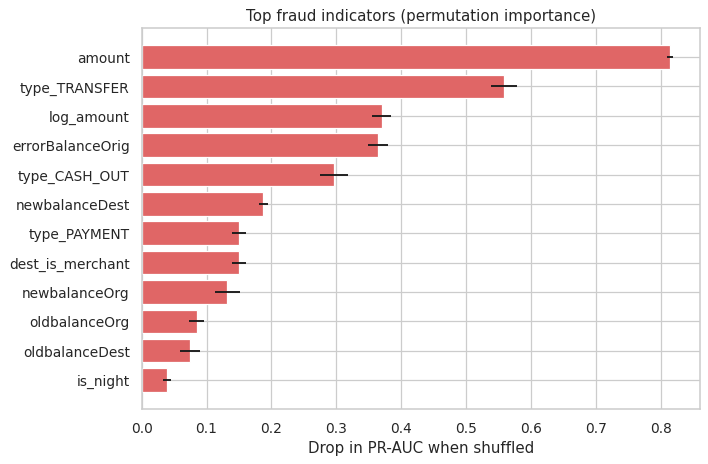

In [32]:
pi = permutation_importance(best_model, X_test, y_test, scoring="average_precision", n_repeats=5, random_state=RS, n_jobs=1)
imp = pd.DataFrame({"feature": X_test.columns, "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance", ascending=False).reset_index(drop=True)
top = imp.head(12).iloc[::-1]
plt.figure(figsize=(8, 5.5))
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="#e06666")
plt.xlabel("Drop in PR-AUC when shuffled")
plt.title("Top fraud indicators (permutation importance)")
plt.show()
imp.head(12).round(4)

In [33]:
# Tree-based importance for comparison (if the selected model exposes it)
mdl = best_model.named_steps["model"]
if hasattr(mdl, "feature_importances_"):
    fi = pd.Series(mdl.feature_importances_, index=X_test.columns).sort_values(ascending=False).head(10)
    print("Built-in feature importance (top 10):")
    print(fi.round(3).to_string())
else:
    print("Selected model has no built-in importances; permutation importance above is used.")

Selected model has no built-in importances; permutation importance above is used.


## 13. Risk analysis
Scores are grouped into actionable **risk tiers** so analysts and systems can respond proportionately.

In [34]:
risk = te[["isFraud", "proba", "amount", "type"]].copy()
risk["tier"] = pd.cut(risk["proba"], bins=[-0.01, 0.10, 0.50, 1.0], labels=["Low (<0.10)", "Medium (0.10-0.50)", "High (>0.50)"])
tier = risk.groupby("tier", observed=True).agg(transactions=("isFraud", "size"), frauds=("isFraud", "sum"), fraud_rate=("isFraud", "mean"), money_in_frauds=("amount", lambda s: s[risk.loc[s.index, "isFraud"] == 1].sum()))
tier["fraud_rate_%"] = (tier["fraud_rate"] * 100).round(2)
tier["share_of_all_frauds_%"] = (tier["frauds"] / risk["isFraud"].sum() * 100).round(1)
tier["share_of_transactions_%"] = (tier["transactions"] / len(risk) * 100).round(2)
tier.drop(columns="fraud_rate")

,transactions,frauds,money_in_frauds,fraud_rate_%,share_of_all_frauds_%,share_of_transactions_%
tier,,,,,,
Low (<0.10),14208,1,"10,298,634.41",0.01,0.60,94.72
Medium (0.10-0.50),408,1,"69,045.88",0.25,0.60,2.72
High (>0.50),384,160,"83,560,701.82",41.67,98.80,2.56


In [35]:
# Safety check: how does the model score the highest-value frauds?
big = risk[risk["isFraud"] == 1].sort_values("amount", ascending=False).head(5)
big[["type", "amount", "proba"]].assign(tier=big["tier"].astype(str))

,type,amount,proba,tier
5761,CASH_OUT,"10,298,634.41",0.00,Low (<0.10)
19193,CASH_OUT,"3,775,249.93",1.00,High (>0.50)
11964,TRANSFER,"2,768,624.59",1.00,High (>0.50)
36595,CASH_OUT,"2,594,706.38",1.00,High (>0.50)
1977,TRANSFER,"1,836,998.33",1.00,High (>0.50)


High-value frauds deserve individual attention: if any of the largest frauds is scored low, a simple **amount-based safety rule** (e.g. always review very large transfers/cash-outs that empty an account) should sit alongside the model.

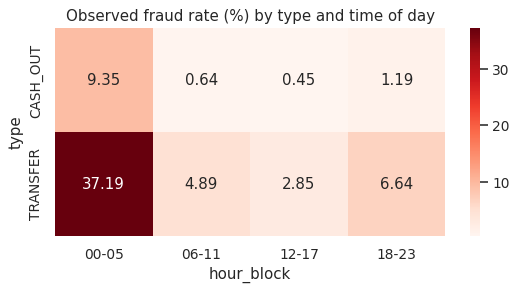

In [36]:
# Risk by transaction type and hour (observed fraud rate)
heat = df.assign(hour_block=pd.cut(df["hour"], [-1, 5, 11, 17, 23], labels=["00-05", "06-11", "12-17", "18-23"]))
heat = heat[heat["type"].isin(["TRANSFER", "CASH_OUT"])].pivot_table(index="type", columns="hour_block", values="isFraud", aggfunc="mean", observed=True) * 100
plt.figure(figsize=(7, 3))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="Reds")
plt.title("Observed fraud rate (%) by type and time of day")
plt.show()

To catch 50% of fraud, review the top 86 transactions (0.57% of volume)
To catch 80% of fraud, review the top 164 transactions (1.09% of volume)
To catch 90% of fraud, review the top 227 transactions (1.51% of volume)
To catch 95% of fraud, review the top 262 transactions (1.75% of volume)


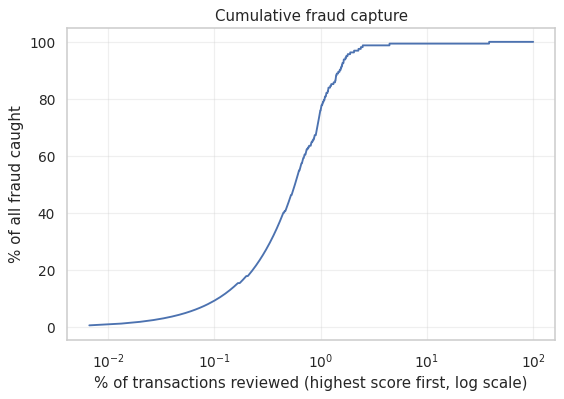

In [37]:
# Alerts workload: how many transactions must analysts review to catch X% of fraud?
order = risk.sort_values("proba", ascending=False).reset_index(drop=True)
order["cum_fraud_%"] = order["isFraud"].cumsum() / order["isFraud"].sum() * 100
order["reviewed_%"] = (order.index + 1) / len(order) * 100
plt.figure(figsize=(7, 4.5))
plt.plot(order["reviewed_%"], order["cum_fraud_%"])
plt.xscale("log")
plt.xlabel("% of transactions reviewed (highest score first, log scale)")
plt.ylabel("% of all fraud caught")
plt.title("Cumulative fraud capture")
plt.grid(alpha=0.3)
plt.show()
for target in (50, 80, 90, 95):
    n = int((order["cum_fraud_%"] < target).sum()) + 1
    print("To catch %d%% of fraud, review the top %d transactions (%.2f%% of volume)" % (target, n, n / len(order) * 100))

In [38]:
import os
os.makedirs("../outputs", exist_ok=True)
flagged = te.loc[te["proba"] >= OP_THR, ["type", "amount", "oldbalanceOrg", "newbalanceOrg", "oldbalanceDest", "newbalanceDest", "hour", "proba", "isFraud"]]
flagged = flagged.sort_values("proba", ascending=False)
flagged.to_csv("../outputs/fraud_flagged_transactions_test.csv", index_label="row_id")
print("Saved %d flagged test transactions to ../outputs/fraud_flagged_transactions_test.csv" % len(flagged))
flagged.head()

Saved 182 flagged test transactions to ../outputs/fraud_flagged_transactions_test.csv


,type,amount,oldbalanceOrg,newbalanceOrg,oldbalanceDest,newbalanceDest,hour,proba,isFraud
36595,CASH_OUT,"2,594,706.38","2,594,706.38",0.00,"12,355.40","12,355.40",23,1.00,1
1977,TRANSFER,"1,836,998.33","1,836,998.33",0.00,0.00,0.00,5,1.00,1
11964,TRANSFER,"2,768,624.59","2,768,624.59",0.00,869.78,"2,769,494.37",10,1.00,1
1879,TRANSFER,"1,479,446.50","1,479,446.50",0.00,0.00,0.00,0,1.00,1
7650,TRANSFER,"1,431,270.68","1,460,660.40","29,389.72","1,026.18","1,026.18",0,1.00,1


## 14. Observations and recommendations for improving fraud detection

**Observations**
1. Fraud is rare (~1 % here, far lower in real data) and confined to `TRANSFER` and `CASH_OUT`; other types can be excluded from the model or handled with simple rules.
2. The EDA shows fraud concentrated in **account-draining transfers**, **large amounts**, **night-time activity** and destination accounts whose balance does not grow; the model's importance ranking highlights amount, transaction type, and the sender/receiver **balance-consistency features**, with night-time activity also contributing.
3. The existing fixed-amount rule has poor recall and precision; the models raise recall substantially while keeping the alert volume manageable.
4. PR-AUC and the precision-recall curve are the right yardsticks. ROC-AUC alone is flattering because legitimate transactions dominate.
5. Remaining errors are explainable: missed frauds resemble ordinary transfers; false alarms are genuine large account-emptying transactions.

**Recommendations**
1. **Tiered response instead of a single block/allow decision.** High-risk → hold and verify; Medium-risk → step-up authentication (OTP / call-back); Low-risk → pass silently. This limits customer friction from false positives.
2. **Layer simple rules with the model.** Keep hard rules for obvious cases (e.g. full-balance transfer to a brand-new beneficiary at night) and use the model to rank everything else.
3. **Tune the threshold to business costs.** Re-estimate the real cost of a missed fraud and of reviewing a false alert, then re-run Section 10 — the best threshold can differ a lot from 0.5.
4. **Add richer signals.** Customer history and velocity (transactions per hour/day, new vs known beneficiary, sudden change in typical amount), device/IP/geo-location and account age typically give the largest accuracy gains.
5. **Network features.** Track destination accounts that receive money from many senders and cash out immediately (mule accounts).
6. **Close the feedback loop.** Feed analyst decisions back as labels, retrain regularly, and monitor precision, recall and score drift because fraudsters change tactics.
7. **Validate on time-based splits** (train on earlier days, test on later days) before going live, and consider cost-sensitive learning or anomaly-detection models as complements.

**Limitations:** the practice dataset is synthetic; balance-derived features are extremely informative on PaySim-style data and may be weaker on real banking data; the review cost used for the cost-based threshold is an assumption.